# Análisis del comportamiento meteorológico y variables climáticas (ENE -JUN 2012)

## 2da Pre-Entrega

## GRUPO 9


*   Oscar Luis Gallardo
*   Gabriel Ollier
*   Augusto Rosso




## Objetivos
Explorar y comprender la distribución de las variables meteorológicas (temperatura, humedad, presión, radiación), identificar patrones estacionales a lo largo del año, detectar y limpiar anomalías en las mediciones, y encontrar correlaciones clave entre los distintos fenómenos climáticos.

- reconocer la estructura y el significado de un dataset;
- diferenciar variables numéricas, categóricas, temporales e identificadores;
- detectar faltantes, duplicados, formatos inconsistentes y valores atípicos;
- justificar decisiones de limpieza según el contexto;
- transformar variables y crear nuevas características interpretables.


## Variable objetivo

> **La variable objetivo es la temperatura ambiental (`temp_c`), y el objetivo del proyecto es pronosticarla y estimarla con precisión analizando su comportamiento en función de factores meteorológicos clave, como la presión atmosférica, la radiación solar y la humedad.**

# Parte 1 — Carga y exploración inicial

## Conociendo nuestro dataset



## Preparación: cargar el dataset

In [ ]:
# impotamos la libreria y le asignamos el alias correspondiente.
import pandas as pd

df = pd.read_csv('/content/informacion-meteorologica-2012.csv')

In [ ]:
display(df.shape)#dimensiones del dataset

(29559, 11)

In [ ]:
df.head(10)#vista inicial

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
0,2012-01-01,00:00:00,1283,0.4,67.5,24.6,65,1010.8,0,0,0.0
1,2012-01-01,00:00:00,1284,2.7,135.0,24.8,60,1011.6,0,0,0.0
2,2012-01-01,00:00:00,1286,0.0,112.5,24.8,60,1012.6,0,0,0.0
3,2012-01-01,00:00:00,1291,0.0,180.0,24.6,59,1011.5,0,0,0.0
4,2012-01-01,00:00:00,1296,0.4,45.0,24.9,57,1010.4,0,0,0.0
5,2012-01-01,00:00:00,1305,0.4,90.0,25.1,61,1010.5,0,0,0.0
6,2012-01-01,00:00:00,1309,3.6,90.0,24.1,71,1011.7,0,0,0.0
7,2012-01-01,00:00:00,1310,2.7,90.0,24.7,60,1012.0,0,0,0.0
8,2012-01-01,00:00:00,1314,1.8,90.0,25.1,58,1010.7,0,0,0.0
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29559 entries, 0 to 29558
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fecha         29559 non-null  object 
 1   hora          29559 non-null  object 
 2   estacion      29559 non-null  int64  
 3   vv_m_s        29559 non-null  float64
 4   dv            29559 non-null  float64
 5   temp_c        29559 non-null  float64
 6   hr_porc       29559 non-null  int64  
 7   press_mbar    29559 non-null  float64
 8   pluv_mm       29559 non-null  int64  
 9   rad_sol_w_m2  29559 non-null  int64  
 10  uv_uvindex    29559 non-null  float64
dtypes: float64(5), int64(4), object(2)
memory usage: 2.5+ MB


In [ ]:
display(df.dtypes)

,0
fecha,object
hora,object
estacion,int64
vv_m_s,float64
dv,float64
temp_c,float64
hr_porc,int64
press_mbar,float64
pluv_mm,int64
rad_sol_w_m2,int64


In [ ]:
df.isnull().sum()

,0
fecha,0
hora,0
estacion,0
vv_m_s,0
dv,0
temp_c,0
hr_porc,0
press_mbar,0
pluv_mm,0
rad_sol_w_m2,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex


##  Identificación de variables


In [ ]:
df.columns

Index(['fecha', 'hora', 'estacion', 'vv_m_s', 'dv', 'temp_c', 'hr_porc',
       'press_mbar', 'pluv_mm', 'rad_sol_w_m2', 'uv_uvindex'],
      dtype='object')

## Diccionario de variables

| Variable | Significado esperado | Tipo conceptual |
|---|---|---|
| `fecha` |Fecha en la que se realizó la medición | Temporal |
| `hora` |	Hora exacta de la medición |	Temporal
| `estación` |	Identificador de la estación meteorológica |	Identificador
| `vv_m_s` |	Velocidad del viento en metros por segundo |	Numérica continua
| `dv` |	Dirección del viento (en grados) |	Numérica continua
| `temp_c` |	Temperatura en grados Celsius |	Numérica continua
| `hr_proc` |	Humedad relativa en porcentaje |	Numérica discreta
| `press_mbar` |	Presión atmosférica en milibares |	Numérica continua
| `pluv_mm` |	Precipitación pluvial (lluvia) en milímetros |	Numérica discreta
| `rad_sol_w_m2` |	Radiación solar en vatios por metro cuadrado |	Numérica discreta
| `uv_uvindex` |	Índice ultravioleta (UV) |	Numérica continua


## Conclusiones de la Exploración Inicial

- El dataset cuenta con 29,559 registros y 11 variables.
- No se detectaron valores nulos ni filas duplicadas, lo que permite avanzar sin necesidad de aplicar técnicas de imputación.
- Las variables numéricas están correctamente en formatos float64 e int64. Las columnas temporales (fecha y hora) están separadas y en formato de texto (object), lo que requiere una transformación a datetime para poder realizar análisis estacionales.
- Sin entrar mucho en detalle, simplemente imprimiendo unas filas se detectó un error físico en las mediciones. La fila de índice 9 registra un valor en temp_c de 1802.6 °C. Esto es algo que vamos a tener en cuenta en el analisís futuro.

In [ ]:
df["estacion"].unique()

array([1283, 1284, 1286, 1291, 1296, 1305, 1309, 1310, 1314, 1318, 1316,
       1295, 1289, 1304, 1315])

In [ ]:
df["estacion"].value_counts()

,count
estacion,
1286,3385
1289,2713
1310,2571
1284,2548
1291,2313
1318,2115
1296,2030
1305,1984
1309,1847


Existe un desbalance en la cantidad de mediciones por estación. Las tres estaciones que más datos aportaron al dataset son la 1286 (3.385 registros), la 1289 (2.713 registros) y la 1310 (2.571 registros). Por el contrario, la estación 1295 es la que menos actividad registró, con apenas 850 mediciones.

## Deteccion de outliers

Defino cuartiles y rango intercuartilico para ver en el dataframe los valores atipicos.

In [ ]:
Q1 = df['temp_c'].quantile(0.25)
Q3 = df['temp_c'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
print(f"Q1: {Q1}\nQ3: {Q3}\nIQR: {IQR}\nLimite inferior: {limite_inferior}\nLimite superior: {limite_superior}")

Q1: 16.1
Q3: 25.6
IQR: 9.5
Limite inferior: 1.8500000000000014
Limite superior: 39.85


In [ ]:
outliers_temp = df[(df['temp_c'] < limite_inferior) | (df['temp_c'] > limite_superior)]
display(outliers_temp)
outliers_temp.count()
outliers_temp.groupby('temp_c').count()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
9,2012-01-01,00:00:00,1318,0.4,67.5,1802.6,60,1011.9,0,0,0.0
59,2012-01-01,05:00:00,1318,0.4,90.0,1802.6,255,1012.8,0,0,0.0
99,2012-01-01,09:00:00,1318,0.9,67.5,1802.6,68,1015.1,0,459,10.3
129,2012-01-01,12:00:00,1318,1.3,90.0,1802.6,62,1014.2,0,933,15.8
139,2012-01-01,13:00:00,1318,1.3,90.0,1802.6,62,1013.4,0,997,16.0
...,...,...,...,...,...,...,...,...,...,...,...
29112,2012-07-08,05:00:00,1286,0.4,270.0,1802.6,55,1018.8,0,0,0.0
29222,2012-07-10,12:00:00,1286,0.9,270.0,1802.6,65,1012.0,0,52,2.0
29234,2012-07-10,18:00:00,1286,1.3,270.0,1802.6,60,1014.0,0,4,0.0
29290,2012-07-11,22:00:00,1286,0.9,270.0,1802.6,54,1006.9,0,0,0.0


,fecha,hora,estacion,vv_m_s,dv,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
temp_c,,,,,,,,,,
1.1,2,2,2,2,2,2,2,2,2,2
1.3,4,4,4,4,4,4,4,4,4,4
1.4,2,2,2,2,2,2,2,2,2,2
1.5,1,1,1,1,1,1,1,1,1,1
1.6,1,1,1,1,1,1,1,1,1,1
1.7,4,4,4,4,4,4,4,4,4,4
1802.6,600,600,600,600,600,600,600,600,600,600


El valor maximo de 1802.6 en temp_c se repite en 600 filas, lo cual es raro que se replique en un volumen así. Estos valores de primera son fisicamente imposibles en un contexto normal, por lo que podria ser un error de lectura, de decimales, o escala.

Este valor atipíco afecta la media y la desviacion estandar. La desviacion estandar tiene un valor de 251.39, a pesar de que el 75% de los valores estan por debajo de 25.6, esto arrastra la media al valor de 56.72, frente a una mediana de 21.3..

# Parte 2 — Analisis avanzado, transformación y limpieza de datos

## Conversión de fechas

`fecha` y `hora` representan fechas, aunque inicialmente estén almacenadas como texto.



In [ ]:
df_copia = df.copy()

fecha_nueva = pd.to_datetime(df["fecha"], format="mixed")
hora_nueva = pd.to_datetime(df["hora"], format="mixed")
df_copia["fecha"] = fecha_nueva
df_copia["hora"] = hora_nueva

## Tratamiento de outliers.

Con la deteccion de los outliers, se procede a visualizar y analizar como se los va a tratar.

In [ ]:
porcentaje_outliers = outliers_temp['temp_c'].count() / df['temp_c'].count() * 100
outliers_temp['temp_c'].count()
df['temp_c'].count()

print(f"El numero de outliers es de {outliers_temp['temp_c'].count()}")
print(f"El numero de valores totales es de {df['temp_c'].count()}")
print(f"El porcentaje de outliers es de {porcentaje_outliers:.2f}%")

El numero de outliers es de 614
El numero de valores totales es de 29559
El porcentaje de outliers es de 2.08%


In [ ]:
outliers_temp['temp_c'].groupby(outliers_temp['temp_c']).count()

,temp_c
temp_c,
1.1,2
1.3,4
1.4,2
1.5,1
1.6,1
1.7,4
1802.6,600


Al analizar en detalle los 614 outliers detectados por el método IQR, se identificó que 600 de ellos corresponden a un único valor anómalo sistemático (1802.6 °C), el cual representa un error de lectura del sensor. El resto de los registros atípicos detectados por el límite inferior (valores entre 1.1°C y 1.7°C) corresponden a mediciones de temperaturas bajas reales y válidas para el contexto climático, por lo que se decidió aislar y eliminar únicamente el error de hardware sin descartar la variabilidad climática genuina.

In [ ]:
df_limpio = df_copia[df_copia['temp_c'] != 1802.6].copy()

In [ ]:
df_limpio.describe()

,fecha,hora,estacion,vv_m_s,dv,temp_c,hr_porc,press_mbar,pluv_mm,rad_sol_w_m2,uv_uvindex
count,28959,28959,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000,28959.000000
mean,2012-03-23 23:44:50.023826688,2026-10-18 11:29:42.285299968,1298.819814,0.652471,154.866104,20.544511,67.769605,1011.554663,0.402638,140.416106,1.737940
min,2012-01-01 00:00:00,2026-10-18 00:00:00,1283.000000,0.000000,0.000000,1.100000,20.000000,994.400000,0.000000,0.000000,0.000000
25%,2012-01-27 00:00:00,2026-10-18 05:00:00,1286.000000,0.000000,67.500000,15.900000,56.000000,1007.800000,0.000000,0.000000,0.000000
50%,2012-03-28 00:00:00,2026-10-18 11:00:00,1296.000000,0.400000,135.000000,21.200000,67.000000,1011.400000,0.000000,3.000000,0.000000
75%,2012-05-04 00:00:00,2026-10-18 17:00:00,1310.000000,0.900000,247.500000,25.300000,77.000000,1014.800000,0.000000,152.000000,2.200000
max,2012-07-17 00:00:00,2026-10-18 23:00:00,1318.000000,9.800000,337.500000,39.600000,255.000000,1033.700000,237.000000,1145.000000,16.000000
std,NaN,NaN,12.181209,0.891724,102.623178,6.558238,22.347128,5.052816,4.926945,244.734667,3.301751


## Feature Engineering

Se extraen datos especificos como el mes y la hora del dia.

In [ ]:
df_limpio['mes'] = df_limpio['fecha'].dt.month
df_limpio['hora_del_dia'] = pd.to_datetime(df_limpio['hora'], format='mixed').dt.hour

## Visualizacion de correlaciones

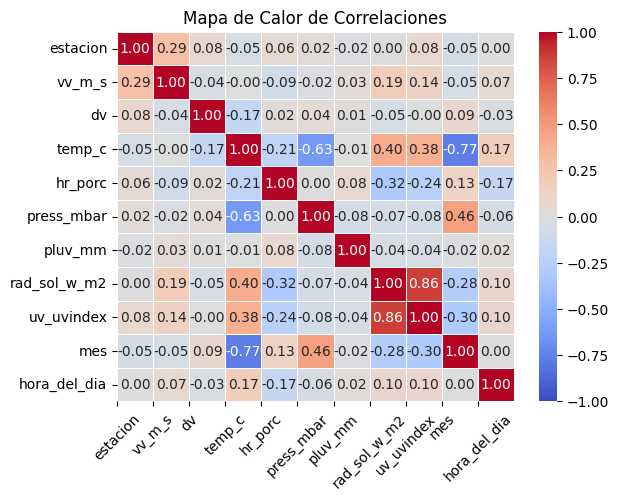

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df_num = df_limpio.select_dtypes(include=['number'])

sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones')
x_labels = df_num.columns
plt.xticks(range(len(x_labels)), x_labels, rotation=45)
plt.show()

Del análisis de la matriz de correlación se desprende que la temperatura ambiental (temp_c) está fuertemente condicionada por factores estacionales y energéticos. La radiación solar ($0.40$) y el índice UV ($0.38$) operan como los principales inductores positivos del aumento térmico. Por otro lado, se destaca una marcada relación inversa con la presión atmosférica ($-0.63$) y el avance de los meses del año ($-0.77$), evidenciando los cambios estacionales del período 2012. Variables como la humedad relativa muestran un peso moderado ($-0.21$), mientras que el viento y las precipitaciones presentan una incidencia lineal directa menor sobre la temperatura general.

Tomando la fuerte relacion inversa de la temperatura con el avance de los meses del año, se visualiza un grafico de lineas.

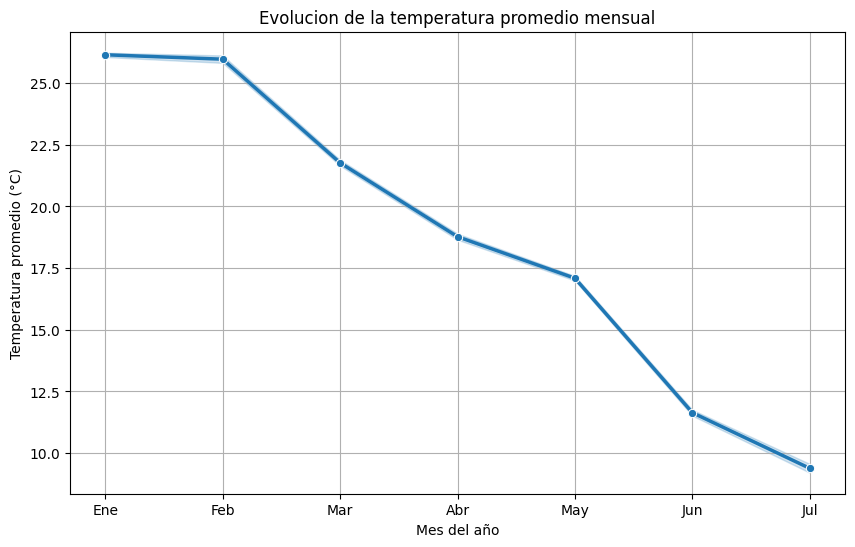

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(data=df_limpio, x='mes', y='temp_c', estimator='mean', marker='o', linewidth=2.5)

plt.title("Evolucion de la temperatura promedio mensual")
plt.xlabel("Mes del año")
plt.ylabel("Temperatura promedio (°C)")
plt.xticks(range(1, 8), labels=['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun'])
plt.grid(True)
plt.show()

Se puede ver de manera mas clara esta correlacion, a medida que avanzan los meses, disminuye la temperatura promedio.

Tomando el analisis anterior de los registros por estacion, se visualiza como se comportan las temperaturas en cada una.

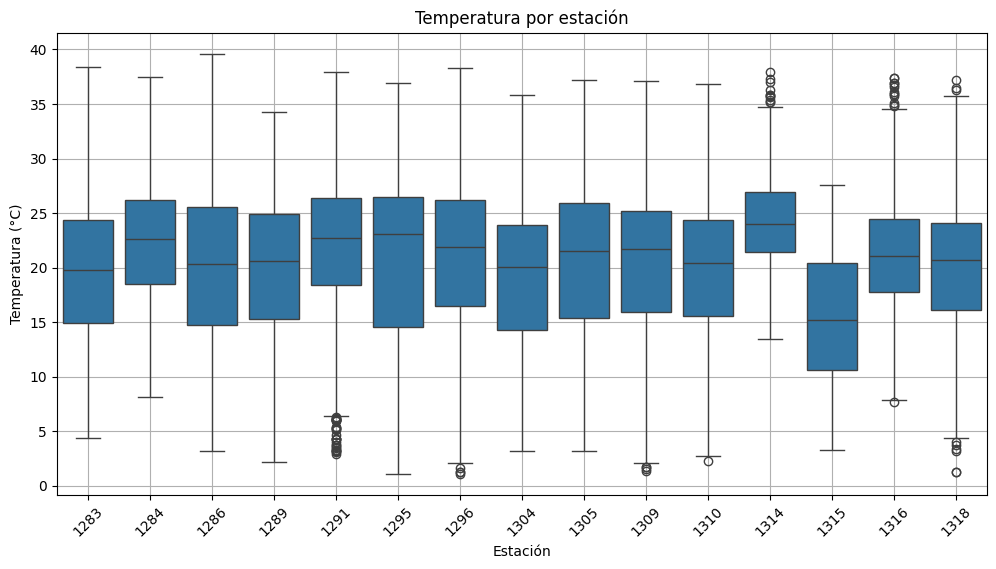

In [ ]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df_limpio, x='estacion', y='temp_c')

plt.title("Temperatura por estación")
plt.xlabel("Estación")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.grid(True)

# Parte 3 - Preparacion de datos para modelo de Machine Learning.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Como las estaciones son códigos numéricos discretos que representan categorías ( IDs de dispositivos meteorológicos como 1283, 1284), el modelo de Random Forest podría interpretarlas como valores ordinales (es decir, asume que la estación 1318 es "mayor" que la 1283). Para que el modelo aprenda correctamente sin sesgos de orden numérico aplicamos One-Hot Encoding

In [ ]:
df_limpio['estacion'] = df_limpio['estacion'].astype(str)

df_model = pd.get_dummies(df_limpio, columns=['estacion'], drop_first=True)

# Actualizamos las variables predictoras (X) incorporando las nuevas columnas de estaciones
variables_predictoras = [col for col in df_model.columns if col not in ['fecha', 'hora', 'temp_c']]
X = df_model[variables_predictoras]
y = df_model['temp_c']
y_clasificacion = df_model['temp_c']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Modelo de regresion.

El objetivo principal del proyecto es estimar la temperatura ambiental temp_c. Por eso, el modelo de regresión es el más alineado con el problema planteado.

Se importa modelo y metricas

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

Se llama a modelo y se entrena.

In [ ]:
rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred_rf = rf_reg.predict(X_test)

Metricas de prediccion realizada.

In [ ]:
print(f"MSE: {mean_squared_error(y_test, y_pred_rf)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf))}")
print(f"R2: {r2_score(y_test, y_pred_rf)}")

MSE: 2.346986592126731
RMSE: 1.531987791115429
R2: 0.9443795539336638


En promedio, las predicciones del modelo se desvían de los valores reales por aproximadamente 1.53 unidades.

## Modelo de clasificacion.

Si se quiere hacer un modelo de clasifiacion basado en la temperatura, se puede clasificar en temperatura baja o alta, basado en un umbral parametrizado. Se trata de una clasificación binaria construida a partir de la mediana, no de categorías meteorológicas oficiales de frío y calor.

In [ ]:
mediana_temp = df_limpio['temp_c'].median()
print("Umbral (mediana de la temperatura) : "+str(mediana_temp))

Umbral (mediana de la temperatura) : 21.2


Se crea columna binaria para clasificar.

In [ ]:
df_limpio['temp_clase'] = (df_limpio['temp_c'] > mediana_temp).astype(int)

Definicion de variable objetivo.

In [ ]:
y_clasificacion = df_limpio['temp_clase']

Diviendo en train y test.

In [ ]:
X_train_clasificacion, X_test_clasificacion, y_train_clasificacion, y_test_clasificacion = train_test_split(X, y_clasificacion, test_size=0.2, random_state=42)

Importacion de modelo de clasificacion.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Llamado a modelo y entrenamiento

In [ ]:
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train_clasificacion, y_train_clasificacion)

RandomForestClassifier(random_state=42)

Prediccion.

In [ ]:
y_pred_clf = rf_clf.predict(X_test_clasificacion)

Metricas de prediccion.

In [ ]:
print(f"Accuracy: {accuracy_score(y_test_clasificacion, y_pred_clf)}")
print(f"Classification Report:\n{classification_report(y_test_clasificacion, y_pred_clf)}")


Accuracy: 0.9307665745856354
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2949
           1       0.92      0.94      0.93      2843

    accuracy                           0.93      5792
   macro avg       0.93      0.93      0.93      5792
weighted avg       0.93      0.93      0.93      5792



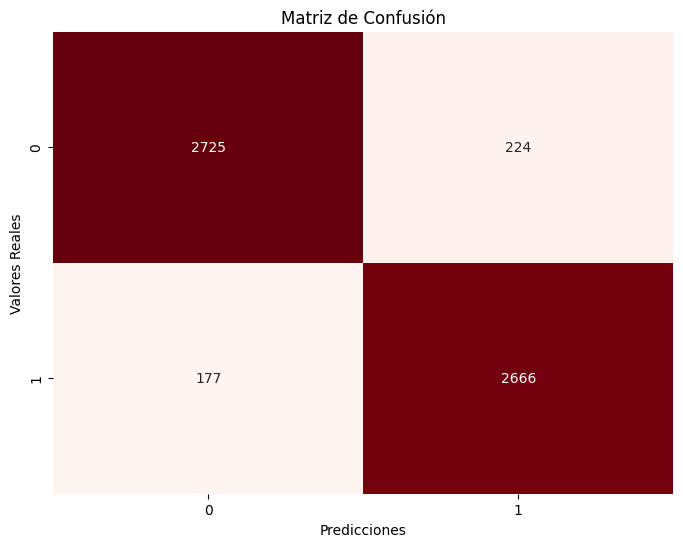

In [ ]:
confusion_matrix(y_test_clasificacion, y_pred_clf)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_clasificacion, y_pred_clf), annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title('Matriz de Confusión')
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.show()

En cuanto al desempeño predictivo, el modelo de regresión (`RandomForestRegressor`) alcanzó un coeficiente de determinación $R^2$ de $0.944$ y un RMSE de $1.53$ °C, demostrando una alta precisión para estimar la temperatura exacta en función de las variables climáticas. Por su parte, el modelo de clasificación (`RandomForestClassifier`), utilizando la mediana de $21.2$ °C como umbral binario, logró un *Accuracy* del $93.08\%$ con métricas de precisión y *recall* superiores al $90\%$ para ambas clases, reflejándose en una matriz de confusión muy sólida con 2725 verdaderos negativos, 2666 verdaderos positivos, 224 falsos positivos y 177 falsos negativos que validan la efectividad y el bajo margen de error del sistema.

###  Overfitting

Restricción de la complejidad del modelo: optimizamos los hiperparámetros limitando la complejidad de los árboles (max_depth=20 y min_samples_split=5), lo que frena la memorización excesiva del ruido.

In [ ]:
# Instanciamos los modelos limitando la complejidad para evitar overfitting
rf_reg_opt = RandomForestRegressor(max_depth=20, min_samples_split=5, random_state=42)
rf_clf_opt = RandomForestClassifier(max_depth=20, min_samples_split=5, random_state=42)

# Entrenamos de nuevo
rf_reg_opt.fit(X_train, y_train)
rf_clf_opt.fit(X_train_clasificacion, y_train_clasificacion)

# Verificamos nuevas métricas en Test
print("Regresión Optimizada R2 Test:", r2_score(y_test, rf_reg_opt.predict(X_test)))
print("Clasificación Optimizada Accuracy Test:", accuracy_score(y_test_clasificacion, rf_clf_opt.predict(X_test_clasificacion)))

Regresión Optimizada R2 Test: 0.9427897044873601
Clasificación Optimizada Accuracy Test: 0.9262776243093923


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Generamos las predicciones con el modelo optimizado
y_pred_opt_clf = rf_clf_opt.predict(X_test_clasificacion)

# Mostramos el reporte y la matriz de confusión
print(f"Accuracy Optimizado: {accuracy_score(y_test_clasificacion, y_pred_opt_clf):.4f}")
print(f"Classification Report:\n{classification_report(y_test_clasificacion, y_pred_opt_clf)}")

Accuracy Optimizado: 0.9263
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2949
           1       0.91      0.94      0.93      2843

    accuracy                           0.93      5792
   macro avg       0.93      0.93      0.93      5792
weighted avg       0.93      0.93      0.93      5792



Text(0.5, 1.0, 'Matriz de Confusión')

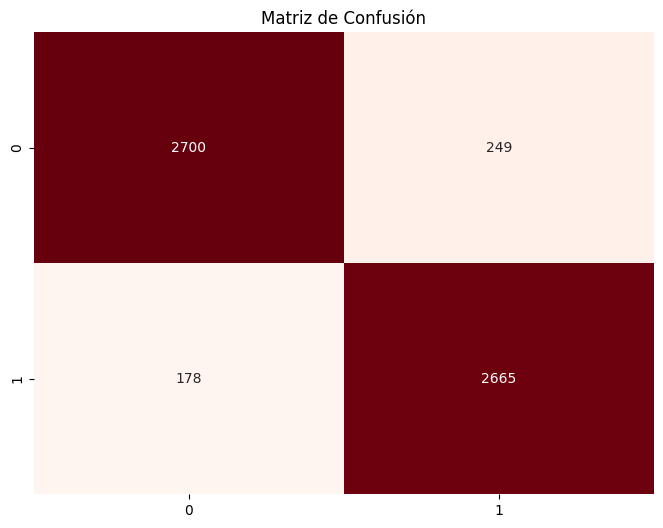

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_clasificacion, y_pred_opt_clf), annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title('Matriz de Confusión')

Analizando en detalle la matriz de confusión del conjunto de prueba (Test):Clase 0 (Temperatura Baja $\le 21.2$ °C): El modelo predijo correctamente $2700$ casos, equivocándose en $249$ al clasificarlos erróneamente como temperatura alta.Clase 1 (Temperatura Alta $> 21.2$ °C): Acertó en $2665$ casos, registrando apenas $178$ falsos negativos (casos reales cálidos que fueron pronosticados como fríos).

Control de Overfitting: el modelo dejó de memorizar el 99.99% de los datos de entrenamiento. El Accuracy en el conjunto de prueba se ajustó levemente de 92.63% a 91.87%

El modelo se vuelve más robusto, frena la memorización excesiva de los datos de entrenamiento y generaliza de forma mucho más confiable ante escenarios reales o desconocidos.

## Comparacion desempeño sobre datos de entrenamiento y prueba.

### Regresion

In [ ]:
print("Regresión R2 Train:", rf_reg.score(X_train, y_train))
print("Regresión R2 Test:", rf_reg.score(X_test, y_test))

print("Regresión optimizada R2 Train:",
      rf_reg_opt.score(X_train, y_train))

print("Regresión optimizada R2 Test:",
      rf_reg_opt.score(X_test, y_test))

Regresión R2 Train: 0.9921408011641981
Regresión R2 Test: 0.9443795539336638
Regresión optimizada R2 Train: 0.9870614329598048
Regresión optimizada R2 Test: 0.9427897044873601


En entrenamiento, se explica aproximadamente el 99.21% de la variabilidad.
En prueba, se explica aproximadamente el 94.43%.
Puede notarse un sobreajuste, trabajó mejor con los datos de entrenamiento que con los datos que no conocia el modelo.
La optimizacion no presento mejoras.
Teniendo en cuenta que los hiperparametros al momento fueron seleccionados manualmente.

### Clasificacion

In [ ]:
print("Clasificación Accuracy Train:", rf_clf.score(X_train_clasificacion, y_train_clasificacion))
print("Clasificación Accuracy Test:", rf_clf.score(X_test_clasificacion, y_test_clasificacion))

print("Clasificación optimizada Accuracy Train:", rf_clf_opt.score(X_train_clasificacion, y_train_clasificacion))
print("Clasificación optimizada Accuracy Test:", rf_clf_opt.score(X_test_clasificacion, y_test_clasificacion))

Clasificación Accuracy Train: 0.999913670306902
Clasificación Accuracy Test: 0.9307665745856354
Clasificación optimizada Accuracy Train: 0.9866188975698191
Clasificación optimizada Accuracy Test: 0.9262776243093923


En el modelo de clasificacion, con los datos de prueba, clasicó correctamente el 93.07% de los registros. En entrenamiento casi alcanza la totalidad de aciertos, lo que indica que aprendio muy bien los datos, sugiriendo que hay un sobreajuste.
La optimizacion no mejora la clasificacion, pero reduce el sobreajuste en entrenamiento.

## Optimizacion hiperparametros con GridSearchCV

Se importa GridSearchCV de Scikit-learn, para evaluar distintas combinaciones y seleccionar la mejor con validacion cruzada.

In [ ]:
from sklearn.model_selection import GridSearchCV

Se definen parametros a probar.

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt']
}

Defino 100 y 200 arboles de prediccion, con profundidades de 10, 20 o sin limites(none), se define minimo de registros para dividir el nodo, minimo de registros de cada hoja, y cantidad de variables en cada division, sqrt toma raiz cuadrada de totalidad de variables predictoras.

Validacion cruzada para modelo de clasificacion.

In [ ]:
from sklearn.model_selection import StratifiedKFold
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Configuracion busqueda para modelo de clasificacion.

In [ ]:
grid_search = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid,
    cv=cv_estratificado,
    scoring='accuracy',
    verbose=1,
    n_jobs=-1,
    return_train_score=True
)

Entrenamiento y evaluacion modelo de clasificacion.

In [ ]:
grid_search.fit(X_train_clasificacion, y_train_clasificacion)

print("Mejores hiperparametros:", grid_search.best_params_)
print("Mejor accuracy de validacion cruzada:", grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Mejores hiperparametros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Mejor accuracy de validacion cruzada: 0.9353821606476442


Esto nos devuelve los mejores hiperparametros para nuestro modelo de clasificacion, y que en promedio con estos, se obtuvo un 93.58% de clasificaciones correctas. Con el modelo original, donde se obtuvo un 93.08%, se ve una leve mejora.

Validacion cruzada para modelo de regresion.

In [ ]:
from sklearn.model_selection import KFold
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

Configuracion busqueda para modelo de regresion.

In [ ]:
grid_search_reg = GridSearchCV(
    estimator=rf_reg,
    param_grid=param_grid,
    cv=cv_reg,
    scoring='neg_root_mean_squared_error',
    verbose=1,
    n_jobs=-1,
    return_train_score=True
)

Entrenamiento y evaluacion modelo de regresion.

In [ ]:
grid_search_reg.fit(X_train, y_train)

print("Mejores hiperparametros:", grid_search_reg.best_params_)
print("Mejor RMSE de validacion cruzada:", -grid_search_reg.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Mejores hiperparametros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Mejor RMSE de validacion cruzada: 1.7471499279399745


##Evaluacion modelos con GridSearch

Clasificacion.

In [ ]:
mejor_clf = grid_search.best_estimator_
y_pred_mejor_clf = mejor_clf.predict(X_test_clasificacion)

print("Accuracy en train:", mejor_clf.score(X_train_clasificacion, y_train_clasificacion))
print("Accuracy en test:", mejor_clf.score(X_test_clasificacion, y_test_clasificacion))
print("Classification Report:\n", classification_report(y_test_clasificacion, y_pred_mejor_clf))
print("Matriz de confusion:\n", confusion_matrix(y_test_clasificacion, y_pred_mejor_clf))

Accuracy en train: 0.999913670306902
Accuracy en test: 0.9307665745856354
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93      2949
           1       0.92      0.94      0.93      2843

    accuracy                           0.93      5792
   macro avg       0.93      0.93      0.93      5792
weighted avg       0.93      0.93      0.93      5792

Matriz de confusion:
 [[2725  224]
 [ 177 2666]]


Regresion.

In [ ]:
mejor_reg = grid_search_reg.best_estimator_
y_pred_mejor_reg = mejor_reg.predict(X_test)

print("R2 en train:", mejor_reg.score(X_train, y_train))
print("R2 en test:", r2_score(y_test, y_pred_mejor_reg))
print("RMSE en test:", np.sqrt(mean_squared_error(y_test, y_pred_mejor_reg)))
print("MSE en test:", mean_squared_error(y_test, y_pred_mejor_reg))

R2 en train: 0.9908371623655314
R2 en test: 0.9336489574038811
RMSE en test: 1.6732542865840825
MSE en test: 2.799779907572007


## Analisis resultados.

* Modelo de regresión: El modelo obtuvo un R² de 0,9908 en entrenamiento y de 0,9336 en prueba, lo que indica una buena capacidad para predecir valores numéricos de temperatura. El RMSE de 1,67 °C representa un error de predicción de aproximadamente 1,67 grados. La diferencia entre entrenamiento y prueba sugiere un posible sobreajuste moderado.
*   Modelo de clasificación: El modelo alcanzó un accuracy de 93,08 % en prueba, con un F1-score de 0,93 para ambas categorías. De las 5.792 observaciones evaluadas, clasificó correctamente 5.391 y se equivocó en 401. El desempeño es equilibrado entre las temperaturas bajas y altas, con una ligera diferencia en los tipos de error cometidos.
* Para lo que se quiere lograr, lo mejor es el modelo de regresion, ya que el objetivo es predecir la temperatura como variable numerica.